<a href="https://colab.research.google.com/github/stcrane-ui/Homework/blob/Assignment-1---Hummingbirds/Assignment_1_Hummingbirds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/EpiPandit/MPM_200/blob/main/Session%205/Assignment%201%20-%20Will%20the%20Hummers%20Survive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🐦 MPM 200 · Week 1 Assignment: *Will the Hummers Survive?*

**Due:** Wednesday 28 October 2026, 9:00 AM · **Total:** 50 points + 5 bonus

**Ground rules**
* Show your work: code **and** output. It lets us follow your thinking and give partial credit.
* Work together, but don't copy. Read each other's code until you could have written it yourself.
* Cells with blanks (`____`) won't run until you fill them in. That's on purpose.

## 📟 Mission briefing

You're the wildlife veterinarian on call for three California wildlife rehabilitation centers. Every year, hummingbirds arrive in shoeboxes and teacups: stunned by windows, carried in by cats, fallen from nests. Some go on to fly again; many don't.

The centers have pooled **more than 25 years of intake records (1991–2016)**. Your mission is to find out **which birds make it back to the sky, and what tips the odds.**

### 🗂️ Case file: data dictionary

| Column | What it records |
|---|---|
| `Admitted` | Date the bird arrived at the center |
| `Disposition_binary` | Outcome: **Died** or **Released** |
| `Place` | Rehabilitation center |
| `F_Aid` | Did the finder give first aid? (Yes/No) |
| `Species_e` | `ANHU` = Anna's Hummingbird · `BCHU` = Black-chinned Hummingbird · `Selasphorus` = orange *Selasphorus* species (e.g., Allen's, Rufous) not identified to species · `Non-selasphorus` = green birds not identified to species |
| `Sex_e`, `Age_e` | Sex and age class as recorded |
| `Brought_in_after` | Days the finder kept the bird before bringing it in |
| `season` | Season of admission |
| `r` | Reason for admission |
| `Green_Orange` | Broad group: green (non-*Selasphorus*) or orange (*Selasphorus*) |
| `ID` | Unique ID for each bird |

## 🍄 Case file 0 · Warm-up: make some noise (2 pts)

**Q0.** Install **beepr** and play the **Mario** sound. Then have a cowsay animal welcome you to the mission (use your name!).

> **Why the helper below?** `beep()` plays sound on the computer *running R*. On Colab that's a Google server with no speakers, so you'd hear nothing. The helper sends the very same sound file to **your browser** instead. On your own laptop, plain `beep("mario")` works.

In [1]:
install.packages(c("beepr", "cowsay"))
library(beepr)
library(cowsay)

# Plays a beepr sound in your browser (for Colab)
beep_colab <- function(sound = "smb_stage_clear") {     # smb_stage_clear = the Mario sound
  wav <- list.files(system.file("sounds", package = "beepr"),
                    pattern = sound, full.names = TRUE)[1]
  b64 <- jsonlite::base64_enc(readBin(wav, "raw", file.info(wav)$size))
  IRdisplay::display_html(sprintf('<audio controls autoplay src="data:audio/wav;base64,%s"></audio>', b64))
}

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘audio’




In [2]:
beep_colab()     # press ▶ if your browser blocks autoplay

say("Welcome to Hummingbird HQ, Dr. Sami!", by = "bat")


 ______________________________________ 
< Welcome to Hummingbird HQ, Dr. Sami! >
 -------------------------------------- 
               \
                \

        __.--'\     \.__./     /'--.__
    _.-'       '.__.'    '.__.'       '-._
  .'                                      '.
 /                                          \
|                                            |
|                                            |
 \         .---.              .---.         /
  '._    .'     '.''.    .''.'     '.    _.'
     '-./            \  /           \.-'
                      ''mrf

In [3]:
library(dplyr)
library(ggplot2)
options(repr.plot.width = 7, repr.plot.height = 4.5)
dir.create("outputs", showWarnings = FALSE)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## 📋 Case file 1 · Intake: read the records

**Q1 (2 pts).** Read `Hummingbird_data.csv` into an object called `data`. It lives on the course GitHub, so you can read it straight from the URL.

In [12]:
url <- "https://raw.githubusercontent.com/EpiPandit/MPM_200_2026/refs/heads/main/data/Hummingbird_data.csv"
Hummingbirds <- read.csv(url)
colnames(Hummingbirds)

[1] "Admitted"           "Disposition_binary" "Place"             
 [4] "F_Aid"              "Species_e"          "Sex_e"             
 [7] "Age_e"              "Brought_in_after"   "season"            
[10] "r"                  "Green_Orange"       "ID"

**Q2 (1 pt).** 🔮 *Predict first:* 26 years, three centers. Guess how many birds: `____`.
Now find how many rows and columns `data` has.

In [13]:
dim(Hummingbirds)      # rows, columns
nrow(Hummingbirds)
ncol(Hummingbirds)

[1] 6908   12

[1] 6908

[1] 12

**Q3 (3 pts).** Check the structure of the data.
* Use `str()` to see each column.
* Use `sapply()` with `class` to list every column's data type.
* Which columns are text (`character`) and which are numbers? Is `Admitted` stored as a date? Note anything that looks odd.

In [14]:
str(Hummingbirds)

data_types <- sapply(Hummingbirds, class)
print(data_types)

'data.frame':	6908 obs. of  12 variables:
 $ Admitted          : chr  "1/2/1991" "1/2/1991" "1/4/1991" "1/5/1991" ...
 $ Disposition_binary: chr  "Died" "Released" "Died" "Died" ...
 $ Place             : chr  "Lindsey" "Lindsey" "Lindsey" "Lindsey" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "ANHU" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "Female-like " "Female-like " "Female-like " "Female-like " ...
 $ Age_e             : chr  "adult-like" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  1 0 0 4 0 0 0 0 0 0 ...
 $ season            : chr  "Winter" "Winter" "Winter" "Winter" ...
 $ r                 : chr  "found on the ground" "unknown" "suspect torpor-like state" "unknown" ...
 $ Green_Orange      : chr  "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "1_ANHU" "2_ANHU" "3_ANHU" "4_ANHU" ...
          Admitted Disposition_binary      

✍️ **Your answer:**

Text columns: Admitted, Disposition_binary, Place, F_Aid, Species_e, Sex_e, Age_e, season, r, Gree_Orange, ID.  A total of 11 columns.

Number columns: Brought_in_after.  A total of one column.

Admitted is not stroed as a date, it is stored as text that is in date format.  

It is strange that calendar (Admission), binary data (Sex_e), and Numeric (Age_e) data are all being stores as text when there is format more suited for their respective values.

### 🎲 Draw your own reproducible sample
Each of you will analyse a random sample of 5,000 birds. `set.seed()` makes "random" **repeatable**: the same seed always gives the same sample, so your instructor can reproduce your results exactly (remember the reproducibility checklist from lecture?).

👉 Replace `1225` with **your birthday as MMDD** (e.g., 3 July → `0703`, which R reads as 703).

In [15]:
set.seed(0409)                              # ← your birthday, MMDD
model_data <- slice_sample(data, n = 5000)

**Use `model_data` for the rest of the assignment.**

**Q4 (1 pt).** How many rows and columns does `model_data` have?

In [17]:
dim(model_data)      # rows, columns
nrow(model_data)
ncol(model_data)

str(model_data)

modeldata_types <- sapply(model_data, class)
print(modeldata_types)

[1] 5000   12

[1] 5000

[1] 12

'data.frame':	5000 obs. of  12 variables:
 $ Admitted          : chr  "6/5/2015" "7/1/1991" "7/18/2014" "2/17/2013" ...
 $ Disposition_binary: chr  "Died" "Died" "Released" "Died" ...
 $ Place             : chr  "malibu" "Lindsey" "Lindsey" "malibu" ...
 $ F_Aid             : chr  "No" "Yes" "No" "No" ...
 $ Species_e         : chr  "Selasphorus" "ANHU" "ANHU" "ANHU" ...
 $ Sex_e             : chr  "unknown" "Female-like " "Male" "Female-like " ...
 $ Age_e             : chr  "Nestling" "adult-like" "adult-like" "adult-like" ...
 $ Brought_in_after  : int  0 0 0 1 23 0 0 0 1 0 ...
 $ season            : chr  "Summer" "Summer" "Summer" "Winter" ...
 $ r                 : chr  "found on the ground" "found on the ground" "caught by domestic animal" "caught by domestic animal" ...
 $ Green_Orange      : chr  "Selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." "Non-selasphorus spp." ...
 $ ID                : chr  "6448_ALHU" "141_ANHU" "5086_ANHU" "5739_ANHU" ...
          Adm

**Q5 (2 pts).** How many columns are **categorical** and how many are **continuous**? Name the continuous one(s). Is `ID` a useful variable for analysis?

✍️ **Your answer:**

Categorical columns: 10 columns including ordinal, nominal, and binary variables.

Continuous columns: Admitted, Brought in after. A total of two columns.

ID assigns a unique tag to each bird patient, making it useful for analyzing counts, repeat visits, and following outcomes.

**Q6 (2 pts).** Save your sample as `Hummingbird_data_YOURNAME.csv` in the `outputs` folder, and submit it. Use `row.names = FALSE`.

In [18]:
write.csv(model_data, "outputs/Hummingbird_data_CRANE.csv", row.names = FALSE)

## 🏥 Case file 2 · Which hospital is busiest?

Let's count how many birds each center admitted (column `Place`), using dplyr to build a summary table and ggplot2 to plot it.

In [19]:
rehab <- model_data %>%
  group_by(Place) %>%
  summarise(count = n_distinct(ID))
rehab

Place,count
<chr>,<int>
Lindsey,4133
Santa Barbara,69
malibu,798


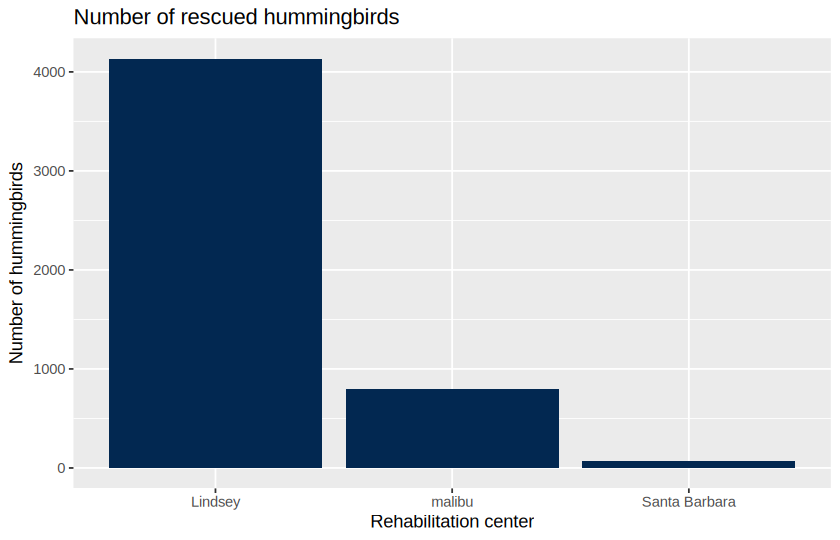

In [20]:
p <- ggplot(rehab, aes(x = Place, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Rehabilitation center") +
  ylab("Number of hummingbirds") +
  labs(title = "Number of rescued hummingbirds")
p

**Q7 (2 pts).** Save this plot as a **PDF, 4 inches wide and 3 inches tall**, and submit it.

In [22]:
ggsave("outputs/rehab_counts_CRANE.pdf", p, width = 4, height = 3)

**Q8 (3 pts).** Explain the code in words, line by line, from the line that creates `rehab` through the plot. What does each function do?

rehab is an an object that uses Model_data as the data range.  Using the pipe operator I can tell R to group the data by the Place column and then pipe again to use the summarize function to assign a total count value of how many unique ID tags are associated with each Place.

ggplot creates "rehab", a plot object where (x=Place) determines the x variable. I have chosen the "place" column to analyze which hospital the bird went to. (y=) determines the y output of count of each x.

geom_col(fill=) allows me to assign a color code to the bars on my plot.

xlab("") deignates a text title to assign to the x-axis.

ylab("") designates a text title for the y-axis

**Q9 (2 pts).** 🤔 Lindsey admitted far more birds than the other centers. Does that mean more birds **die** at Lindsey? Why are raw counts not enough to compare outcomes between centers?

Lindsey admitting more birds doesn't mean they die more often in that area, but that they are being admitted more frequenty.  This could be for a variety of reasons, especially given that patients are brough in by humans.  Lindsey will have a higher death count because they have a higher admission count. I would need to further separate the data to consider both the raw counts of the outcomes for patients, and the relative proportion within hospital admissions.

## 🔬 Case file 3 · Who survives?

**Q10 (6 pts).** Pick **three** variables you think could affect survival (e.g., `F_Aid`, `Age_e`, `r`, `season`, `Sex_e`, `Species_e`).
For **each** variable:
1. Make a table counting unique birds (`ID`) for every combination of the variable and `Disposition_binary`.
2. Plot it as bars, split into panels with `facet_grid()`.

Copy the two cells below for each variable.

In [23]:
df <- model_data %>%
  group_by(Age_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

Age_e,Disposition_binary,count
<chr>,<chr>,<int>
Nestling,Died,424
Nestling,Released,744
adult-like,Died,2811
adult-like,Released,1021


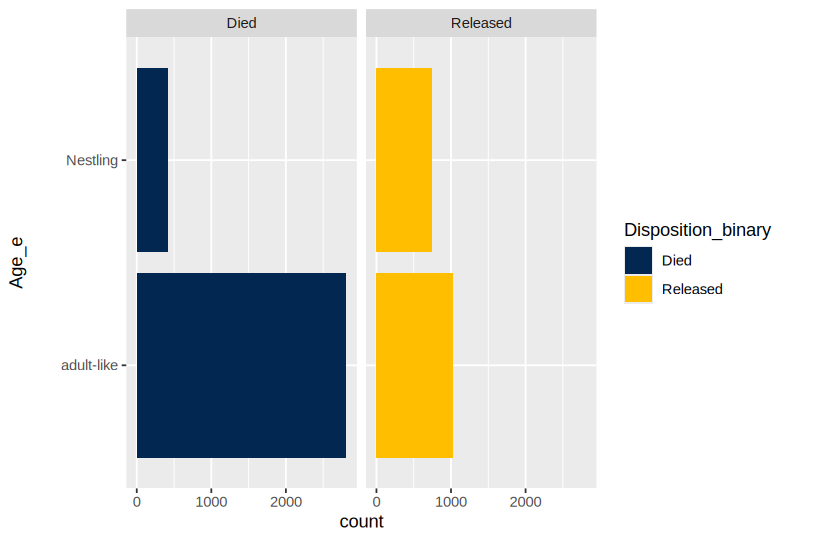

In [24]:
ggplot(df, aes(x = Age_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [26]:
df <- model_data %>%
  group_by(season, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

season,Disposition_binary,count
<chr>,<chr>,<int>
Fall,Died,405
Fall,Released,54
Spring,Died,1302
Spring,Released,921
Summer,Died,980
Summer,Released,600
Winter,Died,548
Winter,Released,190


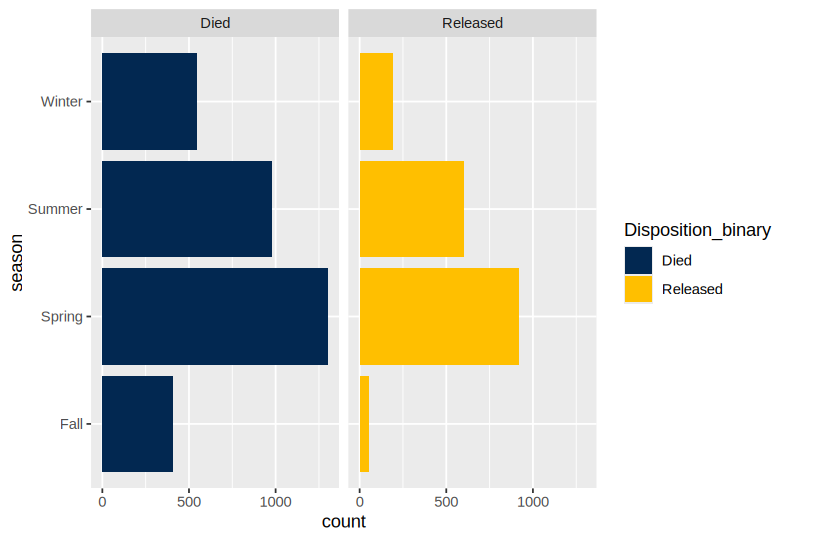

In [27]:
ggplot(df, aes(x = season, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

In [28]:
df <- model_data %>%
  group_by(Sex_e, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")
df

Sex_e,Disposition_binary,count
<chr>,<chr>,<int>
Female-like,Died,2358
Female-like,Released,910
Male,Died,447
Male,Released,111
unknown,Died,430
unknown,Released,744


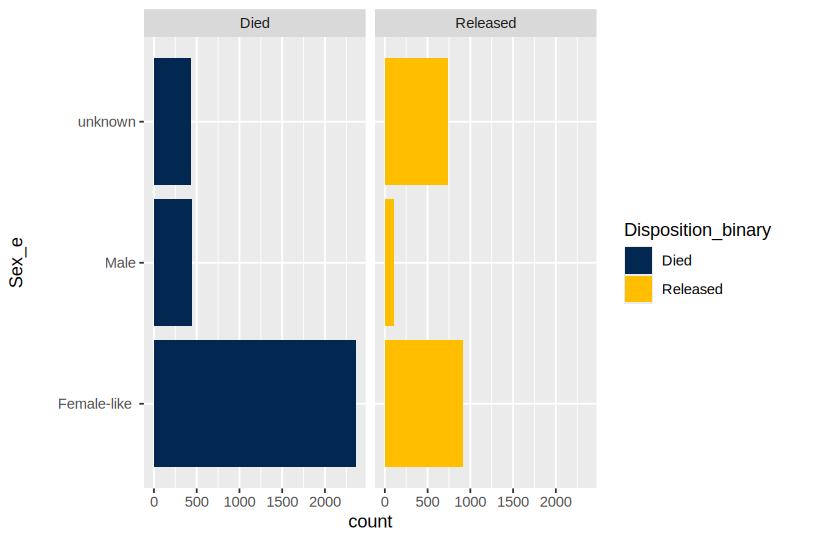

In [29]:
ggplot(df, aes(x = Sex_e, y = count, fill = Disposition_binary)) +
  geom_col() +
  facet_grid(. ~ Disposition_binary) +
  coord_flip() +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

**Q11 (4 pts).** What do your tables and plots suggest? Which variables look associated with the outcome? Which **statistical test** could check whether the association is more than chance?

My tables and plots suggest that there are more admissions of adult females during spring.  Those three classifications are present in some combination in a majority of admission profiles.

### 📊 From counts to proportions
**Q12 (5 pts).** Calculate the proportion of birds **released vs. died** at each center, show the table, and plot it as side-by-side bars.

Place,Disposition_binary,count,proportion
<chr>,<chr>,<int>,<dbl>
Lindsey,Died,2690,0.6508589
Lindsey,Released,1443,0.3491411
Santa Barbara,Died,38,0.5507246
Santa Barbara,Released,31,0.4492754
malibu,Died,507,0.6353383
malibu,Released,291,0.3646617


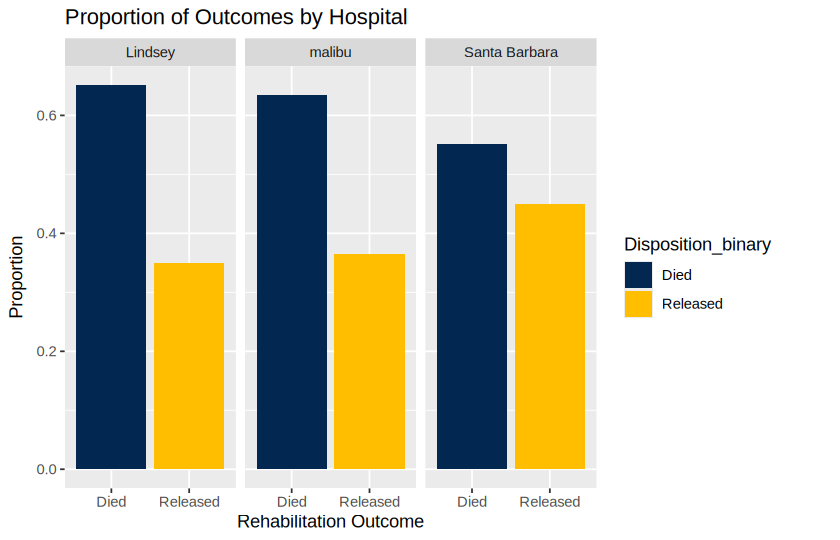

In [31]:
proportions <- model_data %>%
  group_by(Place, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop") %>%
  group_by(Place) %>%
  mutate(proportion = count / sum(count))
proportions

ggplot(proportions, aes(x = Disposition_binary, y = proportion, fill = Disposition_binary)) +
  geom_col(position = "dodge") +
  facet_wrap(~ Place) +
  xlab("Rehabilitation Outcome") +
  ylab("Proportion") +
  labs(title = "Proportion of Outcomes by Hospital") +
  scale_fill_manual(values = c(Died = "#022851", Released = "#FFBF00"))

## 🧬 Case file 4 · Green birds vs. orange birds

**Q13 (5 pts).** Make a new column `Species_group` with two groups:
* **`Selasphorus`**: all *Selasphorus* birds
* **`Non-selasphorus`**: Anna's (ANHU), Black-chinned (BCHU) and unidentified non-*Selasphorus* birds

Then tabulate and plot survival by `Species_group`. **Do survival proportions differ between the groups?**

✅ *Check yourself:* the dataset already has a `Green_Orange` column. If your grouping is right, `table(model_data$Species_group, model_data$Green_Orange)` has zeros off the diagonal.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

There is only **one** value that belongs in the `Selasphorus` group, so a single `ifelse()` does it: *if* `Species_e` is `"Selasphorus"`, then `"Selasphorus"`, *else* `"Non-selasphorus"`.

</details>

                 
                  Non-selasphorus spp. Selasphorus spp.
  Non-selasphorus                 4129                0
  Selasphorus                        0              871

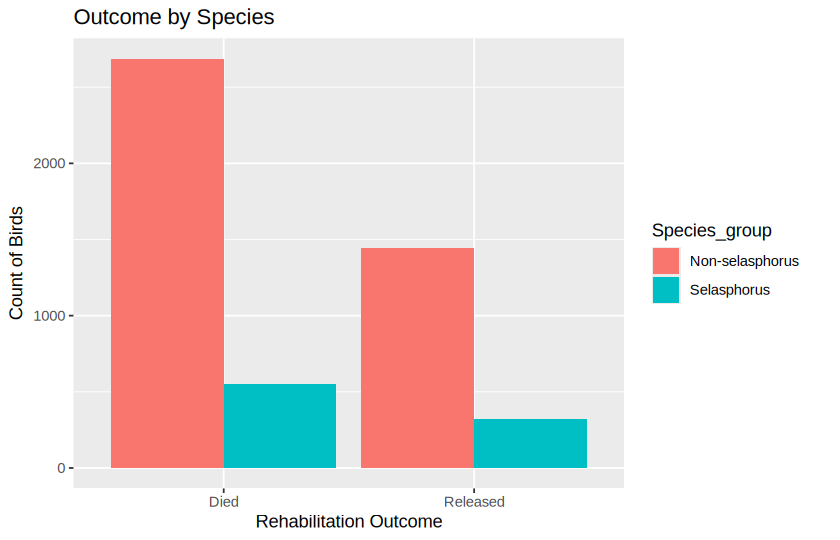

In [36]:
model_data$Species_group <- ifelse(model_data$Species_e == "Selasphorus", "Selasphorus", "Non-selasphorus")

table(model_data$Species_group, model_data$Green_Orange)   # self-check

species_distribution <- model_data %>%
  group_by(Species_group, Disposition_binary) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

ggplot(species_distribution, aes(x = Disposition_binary, y = count, fill = Species_group)) +
  geom_col(position = "dodge") +
  xlab("Rehabilitation Outcome") +
  ylab("Count of Birds") +
  labs(title = "Outcome by Species")

No apparently, both groups seem to die more than they are released.  Non-selasphorus birds make up much more of the population, die more, and survive more than their selasphorus counterparts.

## ⏳ Case file 5 · Time traveller: admissions over the years

**Q14 (2 pts).** Convert `Admitted` to a real date. Then explain what the `format` argument does, and what would happen if you used `"%d/%m/%Y"` instead.

In [39]:
model_data$Admitted_date <- as.Date(model_data$Admitted, format = "%m/%d/%Y")
class(model_data$Admitted_date)
range(model_data$Admitted_date)

[1] "Date"

[1] "1991-01-02" "2016-12-28"

The format argument asks R to read the values in the column and then automatically fill in the date format with the values it finds.

Using the "%d/%m/%Y" format would ascribe the first numerical values as the day, then the month, then the year.  

**Q15 (4 pts).** 🔮 *Predict first:* which **season** do you think brings the most hummingbirds into care? `____` Why?

I think the spring time will have the most admissions.  I saw in my analysis previously that there were more admissions in the spring.  I think this may be because birds are ending their life cycle after their reproductive hase and/or are unable to bounce back after winter hardship (die in torpor)

Now count admissions per **month** and per **year**, and plot both timelines. Was your season prediction right? (`table(model_data$season)` will tell you.)

In [44]:
admissions_by_month <- model_data %>%
  mutate(Admitted_month = format(Admitted_date, "%m")) %>%
  group_by(Admitted_month) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

admissions_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

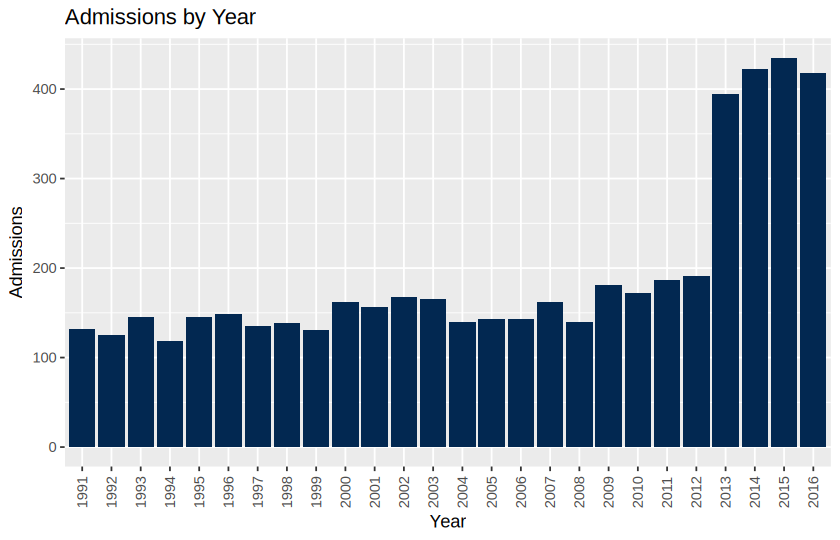

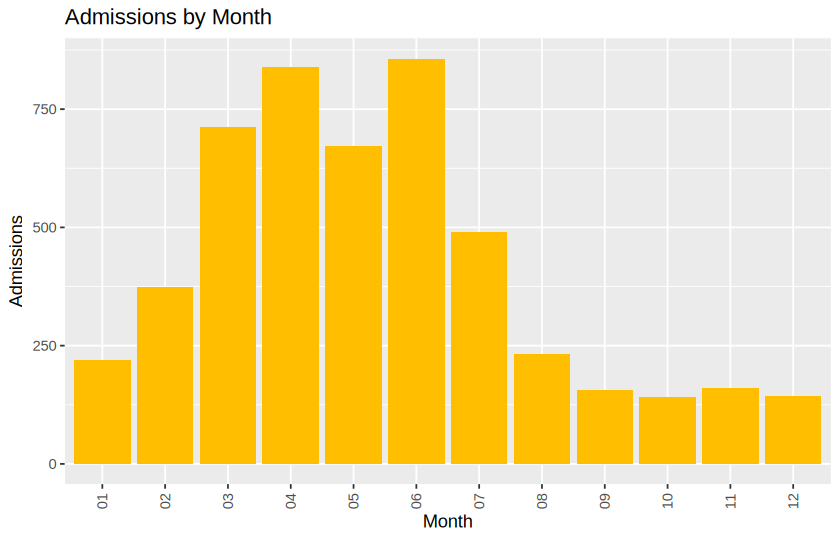

In [45]:
ggplot(admissions_by_year, aes(x = Admitted_year, y = count)) +
  geom_col(fill = "#022851") +
  xlab("Year") +
  ylab("Admissions") +
  labs(title = "Admissions by Year") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

## now plot admissions_by_month the same way
ggplot(admissions_by_month, aes(x = Admitted_month, y = count)) +
  geom_col(fill = "#FFBF00") +
  xlab("Month") +
  ylab("Admissions") +
  labs(title = "Admissions by Month") +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

**Q16 (2 pts).** 🕵️ **Plot twist.** Admissions roughly **triple** from 2013 onwards. Did hummingbirds suddenly get into three times more trouble? Find out what really changed.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Count admissions by year **and** `Place`: `model_data %>% count(Admitted_year = format(Admitted_date, "%Y"), Place)`. When does each center first appear?

</details>

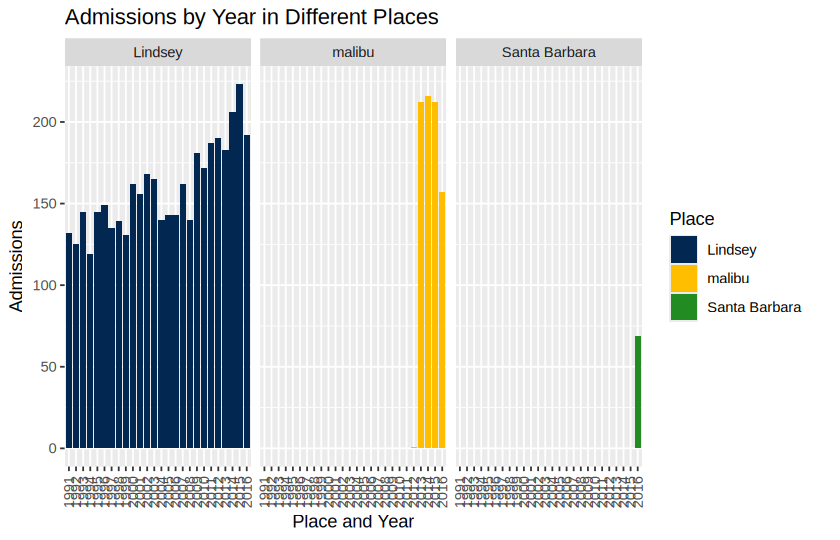

In [49]:
place_by_year <- model_data %>%
  mutate(Admitted_year = format(Admitted_date, "%Y")) %>%
  group_by(Admitted_year, Place) %>%
  summarise(count = n_distinct(ID), .groups = "drop")

ggplot(place_by_year, aes(x = Admitted_year, y = count, fill = Place)) +
  geom_col(position = "dodge") +
  facet_wrap(~ Place) +
  xlab("Place and Year") +
  ylab("Admissions") +
  labs(title = "Admissions by Year in Different Places") +
  scale_fill_manual(values = c(Lindsey = "#022851", malibu = "#FFBF00", `Santa Barbara` = "#228B22")) +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5))

My plots are so ugly 😞.  When I get better at R I can make the plots I had envisioned, but for now I can read this mess.  What I can see is that Lindsey has been reporting admission data consistencl for the duration of my model_data set.  However, Malibu only begins submitting records in 2012-2013, and Santa Barbara beegins in 2016.  The two other hospitals are sporting admission counts similar to or even lower than Lindsey.  Hummingbirds did not expereince some new danger that is causign them to become sick or dead, but rather more hospitals began reporting which caused the data to show spikes at their entries.

## 🕵️ Bonus · Data detective (+5 pts)

Real data are messy, and these data have **at least three problems** hiding in the *raw* file (`data`). Find three, show the code that reveals each one, and say how you would fix it **without overwriting the raw file**.

<details><summary>💡 <b>Hint</b> (try first!)</summary>

Try `summary(data$Brought_in_after)`, `unique(data$Sex_e)` (look *very* closely at the spaces), and `unique(data$Place)` (look at capitalisation).

</details>

In [ ]:
# your detective work here

✍️ **Your answer:**

## 💭 Debrief (2 pts)

**Q17.** In two or three sentences: (a) one thing in this data that surprised you, and (b) one R error you hit and how you fixed it.

One things that surprised me in the data was how dramatic beneficial changes can be.  It is objectively a good thing to have more people contribute to the data, but when Malibu and Santa Barbara join the reporting it creates a false alarm.  Data value is completely dependednt on the quality of analysis and investigation.  Something I struggled with frequently was code syntax.  I was able to overcome this by using AI (built in Gemini) so scan for error and explain why what I was doing was not working.  I ultimately had to write things myself, but acceoting corrections rather than starting from scrathc allowed by to keep my momentum while understanding my scripts.

## 🎨 Hall of Fame (optional, not graded)
Make your **most beautiful** plot from this dataset, in Aggie Blue `#022851` and Aggie Gold `#FFBF00`. The best ones get shown in class. 🏆

## 📤 How to submit
1. Run every cell from the top (**Runtime → Restart and run all**) so the outputs are fresh.
2. Save the notebook to **your branch** of the course GitHub repo: File → Save a copy in GitHub (**never `main`**).
3. Download and submit `Hummingbird_data_YOURNAME.csv` and `rehab_counts_YOURNAME.pdf` from `outputs/`.

In [ ]:
beep_colab("smb_stage_clear")   # mission complete 🍄